In [4]:
import math
import random

In [12]:
class Value:
    def __init__(self, data, _children=(), _op='', label = ''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward
        return out

    def __neg__(self):
        out = Value(-self.data, (self, ), '-')

        def _backward():
            self.grad += -out.grad

        out._backward = _backward
        return out
        
    def __sub__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self + (-other)
        
    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        if other.data == 0:
            raise ZeroDivisionError("Value 的除数不能为 0")
        
        out = Value(self.data / other.data, (self, other), '/')

        def _backward():
            self.grad += out.grad / other.data
            other.grad += out.grad * (-self.data / other.data **2)
        out._backward = _backward
        return out
        
    def __rtruediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return other / self

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward    
        return out 

    def __pow__(self, n):
        out = Value(self.data ** n, (self, ), f'(**{n})')
        def _backward():
            self.grad += out.grad * n * self.data ** (n - 1)
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), 'tanh')
        
        def _backward():
            self.grad += (1 - t**2)*out.grad

        out._backward = _backward
        return out
        
    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)

                for child in v._prev:
                    build_topo(child)

                topo.append(v)
                
        build_topo(self)

        self.grad = 1.0

        for node in reversed(topo):
            node._backward()

In [13]:
x = Value(4.0)
out = 2 / x
out.backward()

print(out.data, x.grad)

0.5 -0.125


In [5]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(0.0)

    def __call__(self, x):
        if len(x) != len(self.w):
            raise ValueError(f"期望 {len(self.w)} 个输入，实际收到 {len(x)} 个")
            
        res = sum([(self.w[i] * (xi if isinstance(xi, Value) else Value(xi)) ) for i, xi in enumerate(x)], self.b)
        return res.tanh()
        
    def parameters(self):
        return [*self.w, self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x): 
        return [n(x) for n in self.neurons]

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, nin, data):
        inputs = [nin, *data]
        self.layers = [Layer(inputs[i], d) for i, d in enumerate(data)]

    def __call__(self, x):
        result = x
        for l in self.layers:
            result = l(result)
        return result

    def parameters(self):
        return [p for l in self.layers for p in l.parameters()]
        
            

In [6]:
def cal_loss(predictions, targets):
    return sum(((prev - t)**2 for prev, t in zip(predictions, targets)), Value(0.0))
origin = [1,2,3,4]
sample2 = [2,5,7,9]
sample3 = [5,2,7,8]
target = [0.23, 0.54, 0.67, 0.01]
random.seed(42)
model = MLP(4, [2, 3, 4])
r = model(origin)
loss = cal_loss(r, target)
old_loss = loss.data
# loss.backward()
 

for _ in range(21):
    for p in model.parameters():
        p.grad = 0.0
    r = model(origin)
    loss = cal_loss(r, target)
    new_loss = loss.data
    loss.backward() 
    for p in model.parameters():
        p.data -= 0.01*p.grad
    print("更新后", new_loss)
model.layers[0].neurons[0].w[0].grad
print("预测：", [v.data for v in model(origin)])
print("目标：", target)



更新后 1.6753166073145256
更新后 1.297906455803178
更新后 1.0947875273818912
更新后 0.9569225765349987
更新后 0.8397350862062216
更新后 0.735743802531555
更新后 0.643091376736923
更新后 0.5609263735746121
更新后 0.4885256940302574
更新后 0.4251143721369568
更新后 0.369856902895179
更新后 0.3218919506290021
更新后 0.28037133495584066
更新后 0.24449082166305924
更新后 0.2135100331024026
更新后 0.18676259925963187
更新后 0.1636588987104627
更新后 0.14368380121950589
更新后 0.12639141827445396
更新后 0.11139834601063311
更新后 0.09837640718110623
预测： [0.10948052381755442, 0.29468449233426103, 0.5620707745308827, -0.01630895512573673]
目标： [0.23, 0.54, 0.67, 0.01]


In [8]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        
        dot.node(name = uid, label = "{ %s | data %.4f ｜ grad %.4f }" % (n.label, n.data, n.grad ), shape='record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)
        
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
            
    return dot

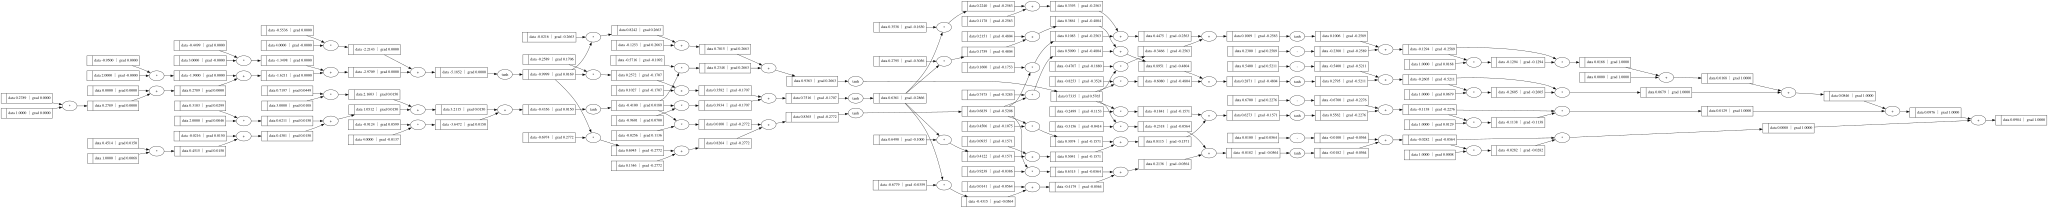

In [9]:
draw_dot(loss)